In [ ]:
%pip -q install kagglehub pandas numpy matplotlib pillow scikit-learn tqdm

MM-IMDb: Multimodal Movie Genre Classification
This notebook compares Poster-only, Plot-only, Early Fusion and Late Fusion approaches for predicting 23 movie genres using images and text.

The experiments used the same dataset split with a random seed of 42, and additional random seeds were used to check how consistently the models performed during training.

In [ ]:
#Importing libraries
import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

random.seed(42)
np.random.seed(42)

print("Libraries imported successfully")


Libraries imported successfully


## 1. Dataset Loading and Exploration

The MM-IMDb dataset contains movie posters, plot summaries and multi-label genre annotations.

In following cell the dataset, examines its structure, checks genre labels and movie identifiers, and explores the distributions of the two modalities.

In [ ]:
## Dataset Loading and Exploration
import kagglehub
from pathlib import Path
from collections import Counter

# Downloading MM-IMDb dataset
dataset_path = kagglehub.dataset_download(
    "johnarevalo/mmimdb"
)

data_dir = Path(dataset_path)

print("Dataset path:", data_dir)
print("Folder exists:", data_dir.exists())

all_files = [
    p for p in data_dir.rglob("*")
    if p.is_file()
]

print("\nTotal files:", len(all_files))

file_types = Counter(
    p.suffix.lower() for p in all_files
)

print("\nFile types:")
for extension, count in file_types.items():
    print(extension or "[no extension]", ":", count)

print("\nDownloaded files:")
for p in all_files[:30]:
    size_mb = p.stat().st_size / (1024 ** 2)
    print(p.relative_to(data_dir), "-", round(size_mb, 2), "MB")


Using Colab cache for faster access to the 'mmimdb' dataset.
Dataset path: /kaggle/input/mmimdb
Folder exists: True

Total files: 2

File types:
.npy : 1
.hdf5 : 1

Downloaded files:
metadata.npy - 61.48 MB
multimodal_imdb.hdf5 - 14916.54 MB


In [ ]:
# Finding the dataset files and checking their paths
import numpy as np
import pandas as pd
import h5py

from pathlib import Path

data_dir = Path(dataset_path)

metadata_path = data_dir / "metadata.npy"
hdf5_path = data_dir / "multimodal_imdb.hdf5"

if not metadata_path.is_file():
    raise FileNotFoundError(
        f"MM-IMDb metadata file not found: {metadata_path}"
    )

if not hdf5_path.is_file():
    raise FileNotFoundError(
        f"MM-IMDb HDF5 file not found: {hdf5_path}"
    )

print("Metadata exists:", metadata_path.exists())
print("HDF5 exists:", hdf5_path.exists())


Metadata exists: True
HDF5 exists: True


In [ ]:

#Loading the information that describes the movies in metadata
metadata = np.load(
    metadata_path,
    allow_pickle=True
).item()

print("Metadata type:", type(metadata))

# Checking whether metadata is a dictionary
if isinstance(metadata, dict):
    print("\nNumber of keys:", len(metadata))
    print("\nFirst 10 keys:")
    print(list(metadata.keys())[:10])

    first_key = next(iter(metadata))
    print("\nFirst metadata entry:")
    print(str(metadata[first_key])[:2000])

else:
    print("\nMetadata preview:")
    print(str(metadata)[:2000])


Metadata type: <class 'dict'>

Number of keys: 4

First 10 keys:
['lookup', 'vocab_size', 'word_to_ix', 'ix_to_word']

First metadata entry:
[[ 8.00781250e-02  1.04980469e-01  4.98046875e-02 ...  3.66210938e-03
   4.76074219e-02 -6.88476562e-02]
 [ 7.03125000e-02  8.69140625e-02  8.78906250e-02 ... -4.76074219e-02
   1.44653320e-02 -6.25000000e-02]
 [ 7.04956055e-03 -7.32421875e-02  1.71875000e-01 ...  1.12304688e-02
   1.64062500e-01  1.06933594e-01]
 ...
 [ 7.51953125e-02  5.54687500e-01 -1.60156250e-01 ... -5.31250000e-01
   2.92968750e-01  2.08007812e-01]
 [ 2.70996094e-02 -2.80380249e-04  1.27929688e-01 ...  9.17968750e-02
  -2.18505859e-02  2.15820312e-01]
 [ 1.27929688e-01 -1.04003906e-01  1.43554688e-01 ... -5.61523438e-02
   1.02050781e-01 -1.06933594e-01]]


In [ ]:

#Checking the structure of HDF5 dataset

import h5py

with h5py.File(hdf5_path, "r") as f:

    print("HDF5 structure:\n")

    for key in f.keys():
        item = f[key]

        print("Name:", key)
        print("Type:", type(item).__name__)

        if isinstance(item, h5py.Dataset):
            print("Shape:", item.shape)
            print("Data type:", item.dtype)

        elif isinstance(item, h5py.Group):
            print("Contains:", list(item.keys())[:10])

        print("-" * 40)


HDF5 structure:

Name: features
Type: Dataset
Shape: (25959, 300)
Data type: float32
----------------------------------------
Name: genres
Type: Dataset
Shape: (25959, 23)
Data type: int32
----------------------------------------
Name: images
Type: Dataset
Shape: (25959, 3, 256, 160)
Data type: int32
----------------------------------------
Name: imdb_ids
Type: Dataset
Shape: (25959,)
Data type: |S7
----------------------------------------
Name: sequences
Type: Dataset
Shape: (25959,)
Data type: object
----------------------------------------
Name: three_grams
Type: Dataset
Shape: (25959, 9946)
Data type: float32
----------------------------------------
Name: vgg_features
Type: Dataset
Shape: (25959, 4096)
Data type: float32
----------------------------------------
Name: word_grams
Type: Dataset
Shape: (25959, 13253)
Data type: float32
----------------------------------------


In [ ]:
#Viewing the available metadata keys
import numpy as np

metadata = np.load(
    metadata_path,
    allow_pickle=True
).item()

print("Metadata keys:")
print(list(metadata.keys()))

print("\nMetadata value types:")

for key, value in metadata.items():
    print(key, ":", type(value).__name__)


Metadata keys:
['lookup', 'vocab_size', 'word_to_ix', 'ix_to_word']

Metadata value types:
lookup : ndarray
vocab_size : int
word_to_ix : dict
ix_to_word : dict


In [ ]:
# Displaying a sample movie poster from the dataset
import h5py
import matplotlib.pyplot as plt

with h5py.File(hdf5_path, "r") as f:

    movie_id = f["imdb_ids"][0].decode("utf-8")
    genre_vector = f["genres"][0]
    image = f["images"][0]
    sequence = f["sequences"][0]

print("Movie ID:", movie_id)
print("Genre vector:", genre_vector)
print("Number of genres:", genre_vector.sum())

print("Image shape:", image.shape)
print("Image minimum:", image.min())
print("Image maximum:", image.max())

print("Text sequence length:", len(sequence))
print("First 20 sequence values:", sequence[:20])


Movie ID: 0028219
Genre vector: [1 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1]
Number of genres: 4
Image shape: (3, 256, 160)
Image minimum: -123
Image maximum: 138
Text sequence length: 204
First 20 sequence values: [18186   418  5100     1  1562    40     7    37   112    18  1805   544
     1   923    18    94     5    10   317    14]


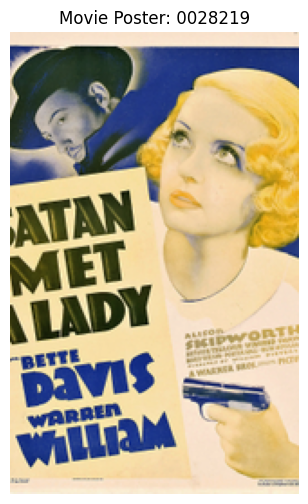

In [ ]:

# Restoring MM-IMDb posters for display

def restore_poster(image_array):
    poster = np.transpose(
        image_array, (1, 2, 0)
    ).astype(np.float32)

    bgr_means = np.array(
        [103.939, 116.779, 123.68],
        dtype=np.float32
    )

    poster = poster + bgr_means
    poster = poster[:, :, ::-1]

    return np.clip(poster, 0, 255).astype(np.uint8)


poster = restore_poster(image)

plt.figure(figsize=(4, 6))
plt.imshow(poster)
plt.title(f"Movie Poster: {movie_id}")
plt.axis("off")
plt.show()


In [ ]:
# Load the names of the 23 movie genres
import h5py
import json

with h5py.File(hdf5_path, "r") as f:
    genre_names = json.loads(
        f["genres"].attrs["target_names"]
    )

for index, name in enumerate(genre_names):
    print(index, name)


0 Drama
1 Comedy
2 Romance
3 Thriller
4 Crime
5 Action
6 Adventure
7 Horror
8 Documentary
9 Mystery
10 Sci-Fi
11 Fantasy
12 Family
13 Biography
14 War
15 History
16 Music
17 Animation
18 Musical
19 Western
20 Sport
21 Short
22 Film-Noir


,Genre Index,Genre,Movie Count
0,0,Drama,13967
1,1,Comedy,8592
2,2,Romance,5364
3,3,Thriller,5192
4,4,Crime,3838
5,5,Action,3550
6,6,Adventure,2710
7,7,Horror,2703
8,8,Documentary,2082
9,9,Mystery,2057


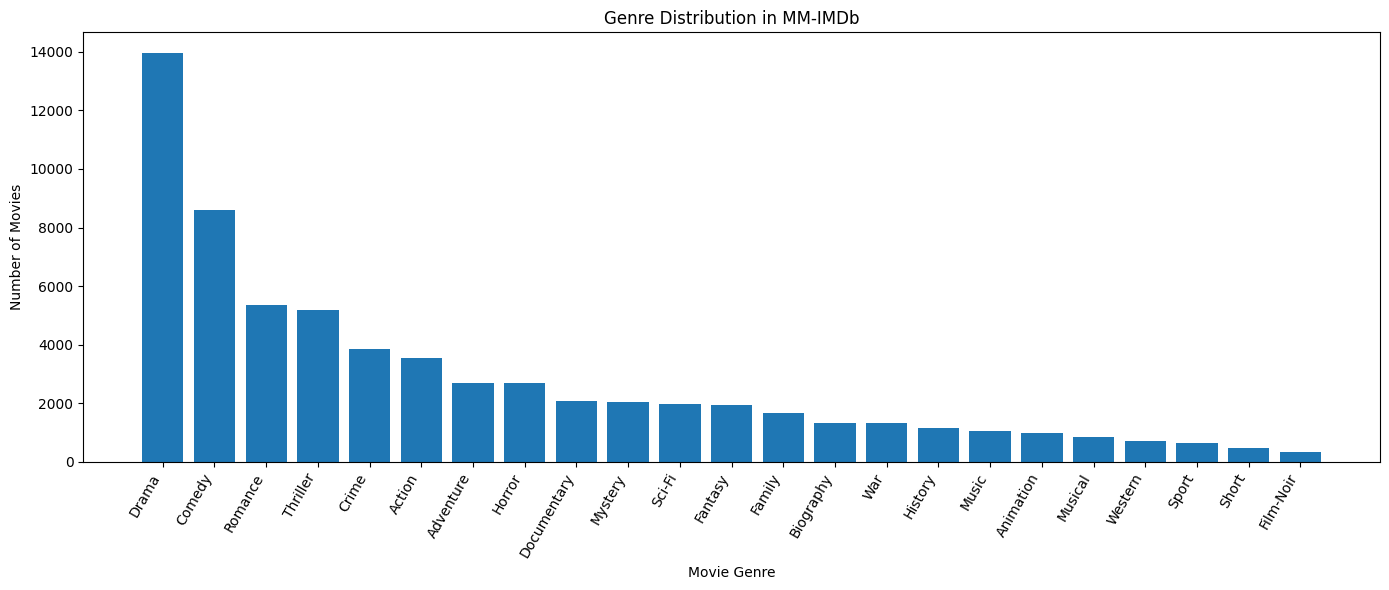

In [ ]:
# Counting the movies in each genre and plot the distribution

import h5py
import json
import pandas as pd
import matplotlib.pyplot as plt

# Loading  genre labels and their original names
with h5py.File(hdf5_path, "r") as f:
    genre_labels = f["genres"][:]

    genre_names = json.loads(
        f["genres"].attrs["target_names"]
    )

# Checking whether the names match the number of label columns
assert len(genre_names) == genre_labels.shape[1]

# Counting movies belonging to each genre
genre_counts = genre_labels.sum(axis=0)

genre_df = pd.DataFrame({
    "Genre Index": range(len(genre_names)),
    "Genre": genre_names,
    "Movie Count": genre_counts
})

display(genre_df)

plt.figure(figsize=(14, 6))

plt.bar(
    genre_df["Genre"],
    genre_df["Movie Count"]
)

plt.title("Genre Distribution in MM-IMDb")
plt.xlabel("Movie Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=60, ha="right")

plt.tight_layout()
plt.show()


Total movies: 25959
Average genres per movie: 2.484648869370931
Minimum genres: 1
Maximum genres: 10


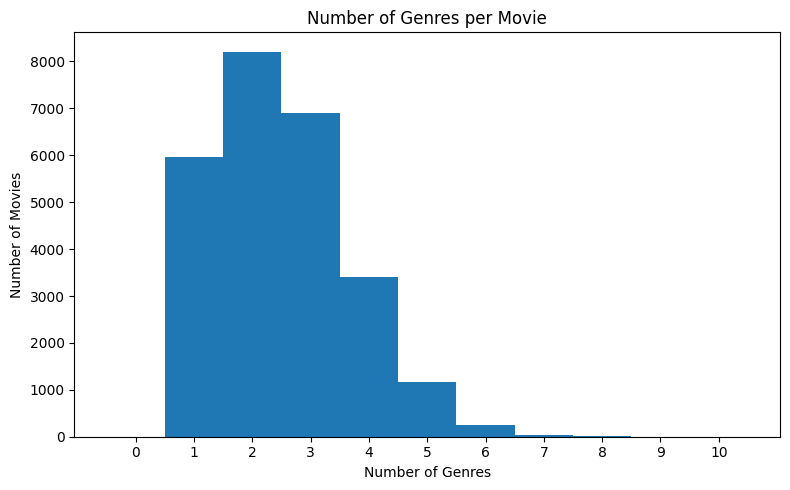

In [ ]:
# Check how many genres are assigned to each movie

genres_per_movie = genre_labels.sum(axis=1)

print("Total movies:", len(genre_labels))
print("Average genres per movie:", genres_per_movie.mean())
print("Minimum genres:", genres_per_movie.min())
print("Maximum genres:", genres_per_movie.max())

plt.figure(figsize=(8, 5))

plt.hist(
    genres_per_movie,
    bins=np.arange(
        genres_per_movie.max() + 2
    ) - 0.5
)

plt.title("Number of Genres per Movie")
plt.xlabel("Number of Genres")
plt.ylabel("Number of Movies")
plt.xticks(range(int(genres_per_movie.max()) + 1))
plt.tight_layout()
plt.show()


In [ ]:
# Checking for missing labels and movies without genres
print("Missing values:", np.isnan(genre_labels).sum())

print("Movies with no genres:",
      np.sum(genre_labels.sum(axis=1) == 0))

print("Unique label values:",
      np.unique(genre_labels))

print("Duplicate movie IDs:")

with h5py.File(hdf5_path, "r") as f:
    ids = f["imdb_ids"][:]

print(len(ids) - len(np.unique(ids)))


Missing values: 0
Movies with no genres: 0
Unique label values: [0 1]
Duplicate movie IDs:
0


In [ ]:

print("Metadata structure:\n")

for key, value in metadata.items():
    print("Key:", key)
    print("Type:", type(value).__name__)

    if hasattr(value, "shape"):
        print("Shape:", value.shape)

    if isinstance(value, dict):
        print("Number of entries:", len(value))
        print("Example keys:", list(value.keys())[:5])

    elif isinstance(value, (list, tuple)):
        print("Length:", len(value))
        print("Example:", str(value[:3])[:300])

    else:
        print("Preview:", str(value)[:300])

    print("-" * 40)


Metadata structure:

Key: lookup
Type: ndarray
Shape: (41611, 300)
Preview: [[ 8.00781250e-02  1.04980469e-01  4.98046875e-02 ...  3.66210938e-03
   4.76074219e-02 -6.88476562e-02]
 [ 7.03125000e-02  8.69140625e-02  8.78906250e-02 ... -4.76074219e-02
   1.44653320e-02 -6.25000000e-02]
 [ 7.04956055e-03 -7.32421875e-02  1.71875000e-01 ...  1.12304688e-02
   1.64062500e-01  1
----------------------------------------
Key: vocab_size
Type: int
Preview: 69980
----------------------------------------
Key: word_to_ix
Type: dict
Number of entries: 69980
Example keys: ['complicating', 'shops', 'shiela', 'cosmos', 'aspercel']
----------------------------------------
Key: ix_to_word
Type: dict
Number of entries: 69980
Example keys: [0, 1, 2, 3, 4]
----------------------------------------


In [ ]:
# Checking the shapes of the saved text and image features

with h5py.File(hdf5_path, "r") as f:

    text_features = f["features"][:5]
    image_features = f["vgg_features"][:5]

    print("Text feature shape:", text_features.shape)
    print("Image feature shape:", image_features.shape)

    print("\nText feature sample:")
    print(text_features[0][:10])

    print("\nImage feature sample:")
    print(image_features[0][:10])

    print("\nText sequence sample:")
    print(f["sequences"][0][:20])


Text feature shape: (5, 300)
Image feature shape: (5, 4096)

Text feature sample:
[ 0.06137044  0.02955077  0.04509483  0.05449054 -0.02768782 -0.01383568
  0.02454139 -0.08376398  0.06336015  0.05989859]

Image feature sample:
[0.        0.        0.        0.        3.9483771 0.        0.
 0.        0.        2.3411007]

Text sequence sample:
[18186   418  5100     1  1562    40     7    37   112    18  1805   544
     1   923    18    94     5    10   317    14]


In [ ]:

with h5py.File(hdf5_path, "r") as f:

    for name in ["features", "vgg_features"]:

        sample = f[name][:100]

        print("\nFeature type:", name)
        print("Shape:", sample.shape)

        print("NaN values:", np.isnan(sample).sum())
        print("Infinite values:", np.isinf(sample).sum())

        print("Minimum:", sample.min())
        print("Maximum:", sample.max())



Feature type: features
Shape: (100, 300)
NaN values: 0
Infinite values: 0
Minimum: -0.16725215
Maximum: 0.21916199

Feature type: vgg_features
Shape: (100, 4096)
NaN values: 0
Infinite values: 0
Minimum: 0.0
Maximum: 12.665962


In [ ]:
# Check for duplicate movie IDs
print("Total movies:", len(ids))
print("Unique movie IDs:", len(np.unique(ids)))

print("\nMetadata keys:")
print(list(metadata.keys()))

print("\nHDF5 keys:")
with h5py.File(hdf5_path, "r") as f:
    print(list(f.keys()))


Total movies: 25959
Unique movie IDs: 25959

Metadata keys:
['lookup', 'vocab_size', 'word_to_ix', 'ix_to_word']

HDF5 keys:
['features', 'genres', 'images', 'imdb_ids', 'sequences', 'three_grams', 'vgg_features', 'word_grams']


## 2. Training, Validation and Test Splits

The dataset is divided into training (70%), validation (15%) and test (15%) subsets using seed 42. The same indices are applied to images, text and labels to maintain alignment. Movie identifiers are checked for overlap, and genre coverage is examined across the splits.



In [ ]:
# Split the movies into training, validation and test sets

from sklearn.model_selection import train_test_split

# Confirm every movie has a unique identifier
assert len(ids) == len(np.unique(ids)), (
    "Duplicate movie IDs found. Resolve them before splitting."
)

indices = np.arange(len(ids))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    shuffle=True
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    shuffle=True
)

print("Training movies:", len(train_idx))
print("Validation movies:", len(val_idx))
print("Testing movies:", len(test_idx))

assert len(
    np.concatenate([train_idx, val_idx, test_idx])
) == len(ids)

assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0


Training movies: 18171
Validation movies: 3894
Testing movies: 3894


In [ ]:
# To check that all genres appear in each dataset split

split_summary = pd.DataFrame({
    "Genre Index": np.arange(genre_labels.shape[1]),
    "Train": genre_labels[train_idx].sum(axis=0),
    "Validation": genre_labels[val_idx].sum(axis=0),
    "Test": genre_labels[test_idx].sum(axis=0)
})

display(split_summary)

print("\nGenres absent from training:",
      (split_summary["Train"] == 0).sum())

print("Genres absent from validation:",
      (split_summary["Validation"] == 0).sum())

print("Genres absent from testing:",
      (split_summary["Test"] == 0).sum())


,Genre Index,Train,Validation,Test
0,0,9733,2101,2133
1,1,6041,1304,1247
2,2,3790,782,792
3,3,3614,807,771
4,4,2676,597,565
5,5,2464,559,527
6,6,1917,404,389
7,7,1862,430,411
8,8,1462,293,327
9,9,1418,311,328



Genres absent from training: 0
Genres absent from validation: 0
Genres absent from testing: 0


In [ ]:
# Checking the vocabulary used to store plot summaries

ix_to_word = metadata["ix_to_word"]

print("Vocabulary size:", len(ix_to_word))

print("\nFirst 20 vocabulary entries:")
for key in list(ix_to_word.keys())[:20]:
    print(key, ":", ix_to_word[key])


Vocabulary size: 69980

First 20 vocabulary entries:
0 : _UNK_
1 : ,
2 : the
3 : .
4 : a
5 : and
6 : to
7 : of
8 : in
9 : is
10 : his
11 : '
12 : he
13 : s
14 : -
15 : with
16 : her
17 : that
18 : for
19 : who


In [ ]:
# View a sample plot sequence and its tokens
with h5py.File(hdf5_path, "r") as f:
    sequence = f["sequences"][0]

print("Sequence length:", len(sequence))
print("First 20 IDs:", sequence[:20])

def decode_sequence(sequence, vocabulary):
    words = []

    for token_id in sequence:
        word = vocabulary.get(int(token_id), "")

        if isinstance(word, bytes):
            word = word.decode("utf-8")

        if word:
            words.append(str(word))

    return " ".join(words)

decoded_plot = decode_sequence(
    sequence,
    ix_to_word
)

print("\nRecovered plot:")
print(decoded_plot[:1500])


Sequence length: 204
First 20 IDs: [18186   418  5100     1  1562    40     7    37   112    18  1805   544
     1   923    18    94     5    10   317    14]

Recovered plot:
sardonic detective shane , thrown out of one town for bringing trouble , heads for home and his ex - partner ' s detective agency . the business is in a sad way , and shane , who has had the forethought to provide himself with a N - dollar commission from an old lady on the train , is welcomed with open arms . when pretty valerie purvis walks in the next day willing to pay over the odds to put a tail on the man who did her wrong , shane ' s way with the ladies looks like paying off yet again . but things start to go wrong when his partner is murdered , and shane himself comes home to find his apartment wrecked by a gentlemanly crook who comes back to apologise - - and to tell him a fascinating fairy - story about the fabled horn of roland that looks like not being so mythical after all . miss purvis wants protecti

  0%|          | 0/25959 [00:00<?, ?it/s]

Average sequence length: 124.41276628529604
Median sequence length: 107.0
Maximum sequence length: 1887
90th percentile: 240.0
95th percentile: 301.0


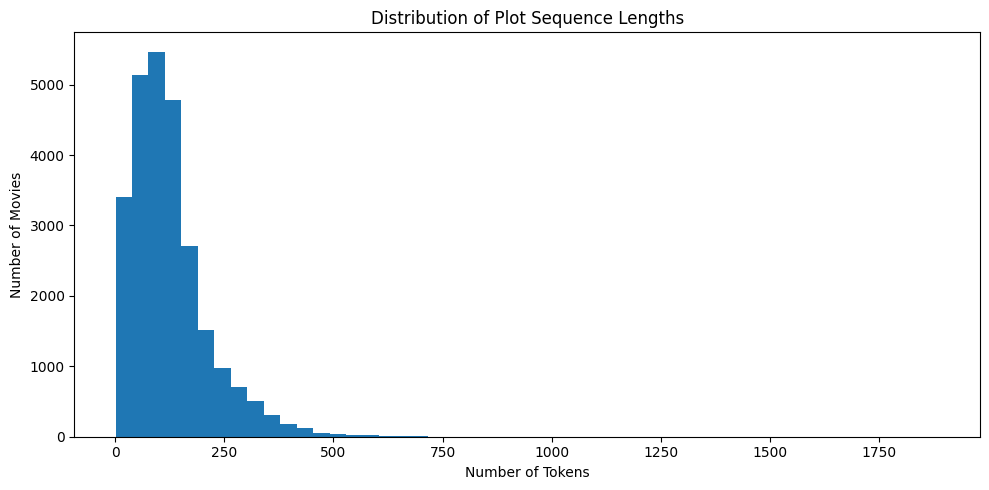

In [ ]:
# Measure and plot the lengths of the plot summaries

sequence_lengths = []

with h5py.File(hdf5_path, "r") as f:
    for i in tqdm(range(len(f["sequences"]))):
        sequence_lengths.append(
            len(f["sequences"][i])
        )

sequence_lengths = np.array(sequence_lengths)

print("Average sequence length:", sequence_lengths.mean())
print("Median sequence length:", np.median(sequence_lengths))
print("Maximum sequence length:", sequence_lengths.max())

print("90th percentile:", np.percentile(sequence_lengths, 90))
print("95th percentile:", np.percentile(sequence_lengths, 95))

plt.figure(figsize=(10, 5))
plt.hist(sequence_lengths, bins=50)

plt.title("Distribution of Plot Sequence Lengths")
plt.xlabel("Number of Tokens")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()


Image shape: (5, 3, 256, 160)
Minimum pixel value: -123
Maximum pixel value: 151


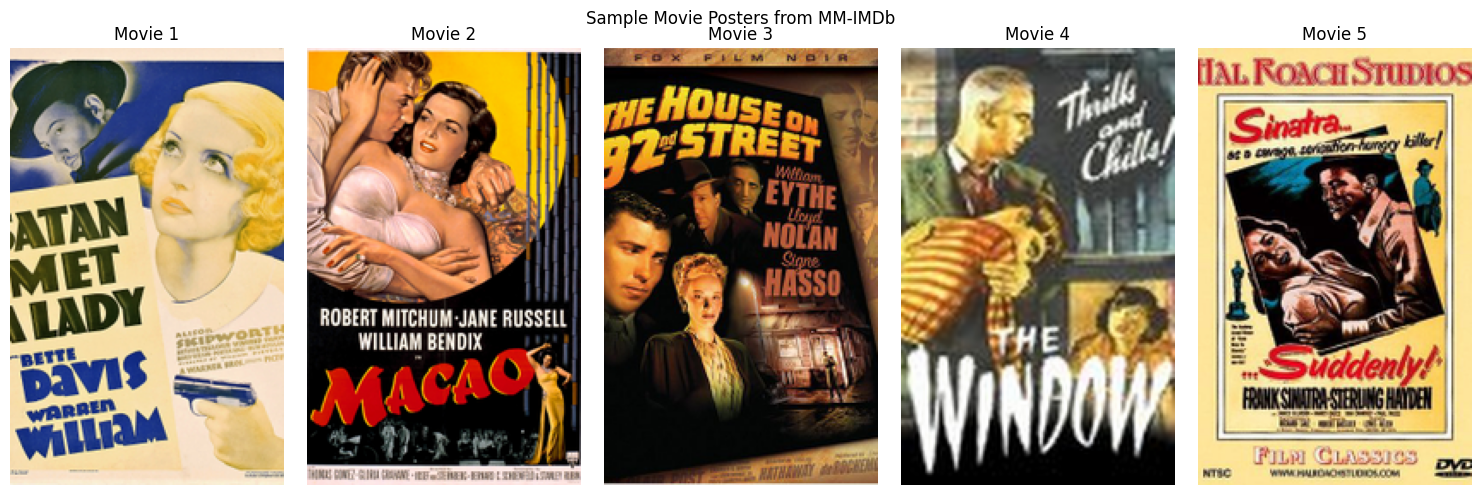

In [ ]:
# Check the shape of the stored poster images
with h5py.File(hdf5_path, "r") as f:
    sample_images = f["images"][:5]

print("Image shape:", sample_images.shape)
print("Minimum pixel value:", sample_images.min())
print("Maximum pixel value:", sample_images.max())

fig, axes = plt.subplots(1, 5, figsize=(15, 5))

for i in range(5):
    poster = restore_poster(sample_images[i])

    axes[i].imshow(poster)
    axes[i].set_title(f"Movie {i + 1}")
    axes[i].axis("off")

plt.suptitle("Sample Movie Posters from MM-IMDb")
plt.tight_layout()
plt.show()


In [ ]:
# Convert stored plot tokens back into readable text

ix_to_word = metadata["ix_to_word"]

def decode_sequence(sequence):
    words = []

    for token in sequence:
        word = ix_to_word.get(int(token), "")

        if isinstance(word, bytes):
            word = word.decode("utf-8")

        if word:
            words.append(str(word))

    return " ".join(words)


with h5py.File(hdf5_path, "r") as f:
    for i in range(3):
        sequence = f["sequences"][i]
        plot = decode_sequence(sequence)

        print(f"\nMovie {i + 1}:")
        print(plot[:600])
        print("-" * 50)



Movie 1:
sardonic detective shane , thrown out of one town for bringing trouble , heads for home and his ex - partner ' s detective agency . the business is in a sad way , and shane , who has had the forethought to provide himself with a N - dollar commission from an old lady on the train , is welcomed with open arms . when pretty valerie purvis walks in the next day willing to pay over the odds to put a tail on the man who did her wrong , shane ' s way with the ladies looks like paying off yet again . but things start to go wrong when his partner is murdered , and shane himself comes home to find his 
--------------------------------------------------

Movie 2:
a sultry night club singer , a man who has also traveled to many exotic ports and a salesman meet aboard ship on the N - mile trip from hong kong to macao . the singer is quickly hired by an american expatriate who runs the biggest casino in macao and has a thriving business in converting hot jewels into cash . her new boss th

In [ ]:
#Check image values before preprocessing
with h5py.File(hdf5_path, "r") as f:
    sample_images = f["images"][:10]

print("Shape:", sample_images.shape)
print("Data type:", sample_images.dtype)
print("Minimum value:", sample_images.min())
print("Maximum value:", sample_images.max())


Shape: (10, 3, 256, 160)
Data type: int32
Minimum value: -123
Maximum value: 151


## 3. Image Feature Extraction

Movie posters are converted into RGB images and prepared using the image processing steps required by the pretrained ResNet-50 model. ResNet-50 is then used to extract 2,048 features from each poster, without changing its pretrained weights.

Images are processed in small batches to reduce memory usage, and the extracted features are saved so they can be used again without repeating the process.

In [ ]:
# Loading PyTorch and the pretrained ResNet-50 tools
##Image Feature Extraction

import torch
from PIL import Image
from torchvision.models import (
    resnet50,
    ResNet50_Weights
)

weights = ResNet50_Weights.DEFAULT
image_transform = weights.transforms()

print(image_transform)


ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [ ]:

# Prepare restored MM-IMDb posters for ResNet-50

def prepare_poster(image_array):
    poster = restore_poster(image_array)

    image = Image.fromarray(poster)

    return image_transform(image)


# Test the preprocessing
with h5py.File(hdf5_path, "r") as f:
    image_array = f["images"][0]

poster_tensor = prepare_poster(image_array)

print("Processed poster shape:", poster_tensor.shape)


Processed poster shape: torch.Size([3, 224, 224])


In [ ]:
# Set the random seed and prepare the image encoder
import torch.nn as nn

torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

image_encoder = resnet50(
    weights=ResNet50_Weights.DEFAULT
)

image_encoder.fc = nn.Identity()

image_encoder = image_encoder.to(device)
image_encoder.eval()

for parameter in image_encoder.parameters():
    parameter.requires_grad = False

print("ResNet-50 ready")


Device: cuda
ResNet-50 ready


In [ ]:
# Test image feature extraction on one poster
with torch.no_grad():
    image_features_test = image_encoder(
        poster_tensor.unsqueeze(0).to(device)
    )

print("Image feature shape:", image_features_test.shape)


Image feature shape: torch.Size([1, 2048])


## 4. Text Feature Extraction

Movie plot summaries are converted back into text and processed using the pretrained bert-base-uncased model. Each plot is limited to 256 tokens, with shorter plots padded to the same length.

BERT is used to extract features from the plots without changing its pretrained weights. The token features are then averaged, excluding padding tokens, to create a 768-dimensional feature vector for each movie.

In [ ]:
# Load the BERT tokenizer and pretrained text model
##Text Feature Extraction

%pip -q install transformers

from transformers import AutoTokenizer, AutoModel

tokenizer = AutoTokenizer.from_pretrained(
    "bert-base-uncased"
)

text_encoder = AutoModel.from_pretrained(
    "bert-base-uncased"
)

text_encoder = text_encoder.to(device)
text_encoder.eval()

for parameter in text_encoder.parameters():
    parameter.requires_grad = False

print("BERT loaded successfully")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT loaded successfully


In [ ]:
# Defining how to extract BERT features from plot summaries
def extract_text_features(text):
    inputs = tokenizer(
        text,
        padding=True,
        truncation=True,
        max_length=256,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = text_encoder(**inputs)

    token_embeddings = outputs.last_hidden_state
    mask = inputs["attention_mask"].unsqueeze(-1)

    masked_embeddings = token_embeddings * mask

    pooled = masked_embeddings.sum(dim=1) / (
        mask.sum(dim=1).clamp(min=1)
    )

    return pooled


with h5py.File(hdf5_path, "r") as f:
    sample_plot = decode_sequence(f["sequences"][0])

assert sample_plot.strip(), "Decoded plot is empty."

text_features_test = extract_text_features(sample_plot)

print("BERT feature shape:", text_features_test.shape)


BERT feature shape: torch.Size([1, 768])


In [ ]:
# Create a folder to save extracted features and results
from pathlib import Path
import torch

output_dir = Path("/content/MMIMDb_Assignment2_2")

output_dir.mkdir(parents=True, exist_ok=True)

print("Output directory:", output_dir)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Output directory: /content/MMIMDb_Assignment2_2
GPU available: True
GPU: Tesla T4


In [ ]:
# Prepare batches of poster images for feature extraction
def extract_image_batch(images):
    processed = [
        prepare_poster(image)
        for image in images
    ]

    batch = torch.stack(processed).to(device)

    with torch.inference_mode():
        features = image_encoder(batch)

    return features.cpu().numpy()


In [ ]:
# Extract and save image features for all movies
from numpy.lib.format import open_memmap
from tqdm.auto import tqdm

batch_size = 32
num_movies = len(ids)

image_feature_path = output_dir / "resnet50_features.npy"

image_embeddings = open_memmap(
    image_feature_path,
    mode="w+",
    dtype="float32",
    shape=(num_movies, 2048)
)

with h5py.File(hdf5_path, "r") as f:

    for start in tqdm(
        range(0, num_movies, batch_size),
        desc="Extracting ResNet-50 features"
    ):
        end = min(start + batch_size, num_movies)

        images = f["images"][start:end]

        features = extract_image_batch(images)

        image_embeddings[start:end] = features

image_embeddings.flush()

print("Image embeddings saved:", image_feature_path)
print("Shape:", image_embeddings.shape)


Extracting ResNet-50 features:   0%|          | 0/812 [00:00<?, ?it/s]

Image embeddings saved: /content/MMIMDb_Assignment2_2/resnet50_features.npy
Shape: (25959, 2048)


In [ ]:
# Prepare batches of plot summaries for BERT
def extract_text_batch(texts):
    inputs = tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=256,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.inference_mode():
        outputs = text_encoder(**inputs)

    token_embeddings = outputs.last_hidden_state

    mask = inputs["attention_mask"].unsqueeze(-1)

    pooled = (
        (token_embeddings * mask).sum(dim=1)
        / mask.sum(dim=1).clamp(min=1)
    )

    return pooled.cpu().numpy()


In [ ]:
# Extract and save text features for all movies
text_batch_size = 16

text_feature_path = output_dir / "bert_features.npy"

text_embeddings = open_memmap(
    text_feature_path,
    mode="w+",
    dtype="float32",
    shape=(num_movies, 768)
)

with h5py.File(hdf5_path, "r") as f:

    for start in tqdm(
        range(0, num_movies, text_batch_size),
        desc="Extracting BERT features"
    ):
        end = min(start + text_batch_size, num_movies)

        sequences = [
            f["sequences"][i]
            for i in range(start, end)
        ]

        texts = [
            decode_sequence(sequence)
            for sequence in sequences
        ]

        features = extract_text_batch(texts)

        text_embeddings[start:end] = features

text_embeddings.flush()

print("Text embeddings saved:", text_feature_path)
print("Shape:", text_embeddings.shape)


Extracting BERT features:   0%|          | 0/1623 [00:00<?, ?it/s]

Text embeddings saved: /content/MMIMDb_Assignment2_2/bert_features.npy
Shape: (25959, 768)


In [ ]:
# Load the saved features and check their dimensions
image_embeddings = np.load(
    image_feature_path,
    mmap_mode="r"
)

text_embeddings = np.load(
    text_feature_path,
    mmap_mode="r"
)

# Display feature dimensions
print("Image features:", image_embeddings.shape)
print("Text features:", text_embeddings.shape)
print("Labels:", genre_labels.shape)

# Checking whether both the modalities align with the genre labels
assert len(image_embeddings) == len(text_embeddings), (
    "Image and text feature counts do not match."
)

assert len(image_embeddings) == len(genre_labels), (
    "Features and genre labels are not aligned."
)

# Checking for invalid feature values
assert np.isfinite(image_embeddings).all(), (
    "Image features contain NaN or infinite values."
)

assert np.isfinite(text_embeddings).all(), (
    "Text features contain NaN or infinite values."
)

print("\nAll modalities are aligned.")
print("All extracted features contain finite values.")

Image features: (25959, 2048)
Text features: (25959, 768)
Labels: (25959, 23)

All modalities are aligned.
All extracted features contain finite values.


In [ ]:
# Save genre labels and dataset split indices
np.save(
    output_dir / "genre_labels.npy",
    genre_labels
)

np.savez(
    output_dir / "data_splits.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

print("Labels and splits saved successfully.")


Labels and splits saved successfully.


## 5. Feature Standardisation and Data Preparation

Image and text features are standardised separately using values calculated from the training data. These same values are used for the validation and test data to avoid data leakage.

PyTorch DataLoaders are then created to prepare the data for model training and evaluation.

In [ ]:
# Import the tools needed for feature standardisation and training
## Feature Standardisation and Data Preparation
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import TensorDataset, DataLoader

image_features = np.load(
    output_dir / "resnet50_features.npy",
    mmap_mode="r"
)

text_features = np.load(
    output_dir / "bert_features.npy",
    mmap_mode="r"
)

labels = np.load(
    output_dir / "genre_labels.npy"
)

splits = np.load(
    output_dir / "data_splits.npz"
)

train_idx = splits["train_idx"]
val_idx = splits["val_idx"]
test_idx = splits["test_idx"]

print("Image features:", image_features.shape)
print("Text features:", text_features.shape)
print("Labels:", labels.shape)
print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))


Image features: (25959, 2048)
Text features: (25959, 768)
Labels: (25959, 23)
Train: 18171
Validation: 3894
Test: 3894


In [ ]:

# Standardise image and text features using training data only

image_mu = image_features[train_idx].mean(axis=0)
image_sd = image_features[train_idx].std(axis=0) + 1e-6

text_mu = text_features[train_idx].mean(axis=0)
text_sd = text_features[train_idx].std(axis=0) + 1e-6

image_scaled = (
    np.asarray(image_features) - image_mu
) / image_sd

text_scaled = (
    np.asarray(text_features) - text_mu
) / text_sd

print("Image shape:", image_scaled.shape)
print("Text shape:", text_scaled.shape)
print("All values finite:",
      np.isfinite(image_scaled).all()
      and np.isfinite(text_scaled).all())


Image shape: (25959, 2048)
Text shape: (25959, 768)
All values finite: True


In [ ]:

# Create DataLoaders using standardised features for training, validation and testing

def create_loader(features, indices, batch_size=64, shuffle=False):

    X = torch.tensor(
        np.asarray(features[indices]).copy(),
        dtype=torch.float32
    )

    y = torch.tensor(
        labels[indices],
        dtype=torch.float32
    )

    dataset = TensorDataset(X, y)

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle
    )


image_train_loader = create_loader(
    image_scaled, train_idx, shuffle=True
)

image_val_loader = create_loader(
    image_scaled, val_idx
)

text_train_loader = create_loader(
    text_scaled, train_idx, shuffle=True
)

text_val_loader = create_loader(
    text_scaled, val_idx
)

print("DataLoaders created successfully.")


DataLoaders created successfully.


## 6. Unimodal Baseline Models

Two separate neural network models are trained, one using movie poster features and the other using plot features. Both models predict 23 possible movie genres using BCEWithLogitsLoss.

These models help us understand how well images and text perform separately before combining them in the multimodal models.

In [ ]:
# Defining the neural network for models that use only images or only text

class GenreClassifier(nn.Module):
    """MLP classifier for multi-label movie genre prediction.

    Accepts pretrained image or text feature vectors and
    produces one logit for each of the 23 movie genres.
    """

    def __init__(self, input_dim, num_classes=23):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.network(x)


image_model = GenreClassifier(
    input_dim=2048
).to(device)

text_model = GenreClassifier(
    input_dim=768
).to(device)

print("Poster-only model:")
print(image_model)

print("\nPlot-only model:")
print(text_model)


Poster-only model:
GenreClassifier(
  (network): Sequential(
    (0): Linear(in_features=2048, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=23, bias=True)
  )
)

Plot-only model:
GenreClassifier(
  (network): Sequential(
    (0): Linear(in_features=768, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=23, bias=True)
  )
)


In [ ]:
# Define the training process and track validation loss
import torch.optim as optim
import copy

def train_model(
    model,
    train_loader,
    val_loader,
    epochs=20,
    learning_rate=0.001
):
    """Train a classifier and restore its best validation checkpoint.

    Uses BCEWithLogitsLoss and monitors validation loss.

    Returns:
        The trained model, training losses and validation losses.
    """

    criterion = nn.BCEWithLogitsLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    train_losses = []
    val_losses = []

    best_val_loss = float("inf")
    best_weights = None

    for epoch in range(epochs):

        model.train()
        running_train_loss = 0

        for X, y in train_loader:
            X = X.to(device)
            y = y.to(device)

            optimizer.zero_grad()

            outputs = model(X)
            loss = criterion(outputs, y)

            loss.backward()
            optimizer.step()

            running_train_loss += (
                loss.item() * X.size(0)
            )

        avg_train_loss = (
            running_train_loss / len(train_loader.dataset)
        )

        model.eval()
        running_val_loss = 0

        with torch.no_grad():
            for X, y in val_loader:
                X = X.to(device)
                y = y.to(device)

                outputs = model(X)
                loss = criterion(outputs, y)

                running_val_loss += (
                    loss.item() * X.size(0)
                )

        avg_val_loss = (
            running_val_loss / len(val_loader.dataset)
        )

        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)

        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            best_weights = copy.deepcopy(
                model.state_dict()
            )

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Val Loss: {avg_val_loss:.4f}"
        )

    model.load_state_dict(best_weights)

    return model, train_losses, val_losses




In [ ]:
# Train the Poster-only model
image_model, image_train_losses, image_val_losses = train_model(
    image_model,
    image_train_loader,
    image_val_loader,
    epochs=20
)

torch.save(
    image_model.state_dict(),
    output_dir / "poster_only_model.pth"
)

print("Poster-only model trained and saved.")


Epoch 1/20 | Train Loss: 0.2723 | Val Loss: 0.2479
Epoch 2/20 | Train Loss: 0.2296 | Val Loss: 0.2504
Epoch 3/20 | Train Loss: 0.2124 | Val Loss: 0.2587
Epoch 4/20 | Train Loss: 0.1976 | Val Loss: 0.2680
Epoch 5/20 | Train Loss: 0.1849 | Val Loss: 0.2791
Epoch 6/20 | Train Loss: 0.1714 | Val Loss: 0.2912
Epoch 7/20 | Train Loss: 0.1586 | Val Loss: 0.3060
Epoch 8/20 | Train Loss: 0.1483 | Val Loss: 0.3194
Epoch 9/20 | Train Loss: 0.1390 | Val Loss: 0.3325
Epoch 10/20 | Train Loss: 0.1298 | Val Loss: 0.3476
Epoch 11/20 | Train Loss: 0.1218 | Val Loss: 0.3637
Epoch 12/20 | Train Loss: 0.1147 | Val Loss: 0.3755
Epoch 13/20 | Train Loss: 0.1075 | Val Loss: 0.3957
Epoch 14/20 | Train Loss: 0.1029 | Val Loss: 0.4076
Epoch 15/20 | Train Loss: 0.0980 | Val Loss: 0.4217
Epoch 16/20 | Train Loss: 0.0933 | Val Loss: 0.4382
Epoch 17/20 | Train Loss: 0.0895 | Val Loss: 0.4509
Epoch 18/20 | Train Loss: 0.0842 | Val Loss: 0.4647
Epoch 19/20 | Train Loss: 0.0816 | Val Loss: 0.4801
Epoch 20/20 | Train L

In [ ]:
# Train the Plot-only model
text_model, text_train_losses, text_val_losses = train_model(
    text_model,
    text_train_loader,
    text_val_loader,
    epochs=20
)

torch.save(
    text_model.state_dict(),
    output_dir / "plot_only_model.pth"
)

print("Plot-only model trained and saved.")


Epoch 1/20 | Train Loss: 0.2107 | Val Loss: 0.1747
Epoch 2/20 | Train Loss: 0.1737 | Val Loss: 0.1724
Epoch 3/20 | Train Loss: 0.1671 | Val Loss: 0.1724
Epoch 4/20 | Train Loss: 0.1624 | Val Loss: 0.1719
Epoch 5/20 | Train Loss: 0.1587 | Val Loss: 0.1726
Epoch 6/20 | Train Loss: 0.1549 | Val Loss: 0.1722
Epoch 7/20 | Train Loss: 0.1521 | Val Loss: 0.1738
Epoch 8/20 | Train Loss: 0.1490 | Val Loss: 0.1758
Epoch 9/20 | Train Loss: 0.1462 | Val Loss: 0.1770
Epoch 10/20 | Train Loss: 0.1438 | Val Loss: 0.1778
Epoch 11/20 | Train Loss: 0.1408 | Val Loss: 0.1795
Epoch 12/20 | Train Loss: 0.1386 | Val Loss: 0.1814
Epoch 13/20 | Train Loss: 0.1359 | Val Loss: 0.1819
Epoch 14/20 | Train Loss: 0.1332 | Val Loss: 0.1833
Epoch 15/20 | Train Loss: 0.1314 | Val Loss: 0.1870
Epoch 16/20 | Train Loss: 0.1295 | Val Loss: 0.1872
Epoch 17/20 | Train Loss: 0.1267 | Val Loss: 0.1884
Epoch 18/20 | Train Loss: 0.1247 | Val Loss: 0.1908
Epoch 19/20 | Train Loss: 0.1229 | Val Loss: 0.1925
Epoch 20/20 | Train L

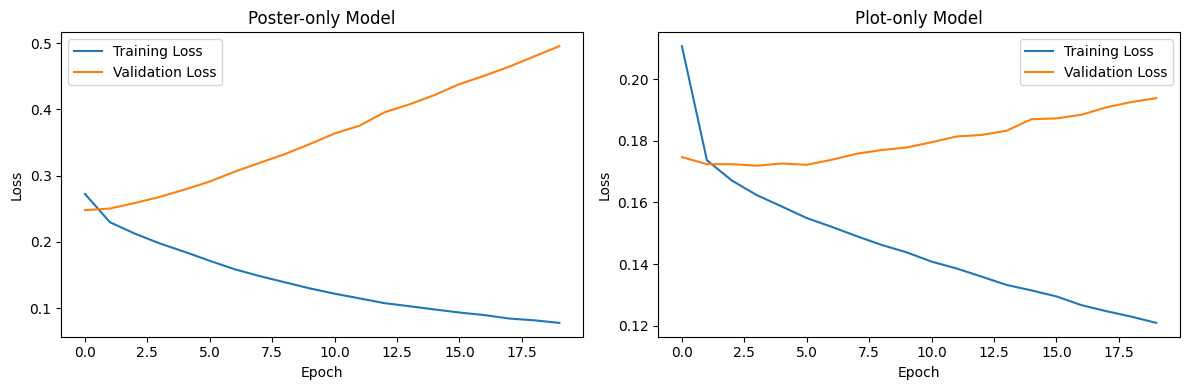

In [ ]:
# Plot training and validation losses for both models
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    image_train_losses,
    label="Training Loss"
)

axes[0].plot(
    image_val_losses,
    label="Validation Loss"
)

axes[0].set_title("Poster-only Model")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()


axes[1].plot(
    text_train_losses,
    label="Training Loss"
)

axes[1].plot(
    text_val_losses,
    label="Validation Loss"
)

axes[1].set_title("Plot-only Model")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()


In [ ]:
# Evaluate model predictions using classification metrics

from sklearn.metrics import f1_score, average_precision_score

def evaluate_model(model, loader, threshold=0.5):
    model.eval()

    all_probs = []
    all_labels = []

    with torch.no_grad():
        for X, y in loader:
            X = X.to(device)

            logits = model(X)
            probabilities = torch.sigmoid(logits)

            all_probs.append(
                probabilities.cpu().numpy()
            )

            all_labels.append(y.numpy())

    y_prob = np.vstack(all_probs)
    y_true = np.vstack(all_labels)

    y_pred = (y_prob >= threshold).astype(int)

    micro_f1 = f1_score(
        y_true, y_pred,
        average="micro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    macro_ap = average_precision_score(
        y_true, y_prob,
        average="macro"
    )

    return {
        "Micro-F1": micro_f1,
        "Macro-F1": macro_f1,
        "Macro-AP": macro_ap
    }


image_results = evaluate_model(
    image_model,
    image_val_loader
)

text_results = evaluate_model(
    text_model,
    text_val_loader
)

results_df = pd.DataFrame(
    [image_results, text_results],
    index=["Poster-only", "Plot-only"]
)

display(results_df)


,Micro-F1,Macro-F1,Macro-AP
Poster-only,0.387494,0.178404,0.314067
Plot-only,0.634950,0.540451,0.630104


## 7. Early Fusion

The 2,048 image features and 768 text features are combined into a single set of 2,816 features.

A neural network is then trained using these combined features to predict movie genres. The results are compared with the Poster-only and Plot-only models to see whether combining images and text improves performance.

In [ ]:
# Combine image and text features for Early Fusion
fusion_features = np.concatenate(
    [image_scaled, text_scaled],
    axis=1
)

print("Image features:", image_features.shape)
print("Text features:", text_features.shape)
print("Combined features:", fusion_features.shape)

assert fusion_features.shape == (len(labels), 2816)
assert np.isfinite(fusion_features).all()


Image features: (25959, 2048)
Text features: (25959, 768)
Combined features: (25959, 2816)


In [ ]:
# Create data loaders for the combined features
fusion_train_loader = create_loader(
    fusion_features,
    train_idx,
    batch_size=64,
    shuffle=True
)

fusion_val_loader = create_loader(
    fusion_features,
    val_idx,
    batch_size=64
)

print("Early-fusion DataLoaders created.")


Early-fusion DataLoaders created.


In [ ]:
# Define the Early Fusion classifier
class EarlyFusionClassifier(nn.Module):
    def __init__(self, input_dim=2816, num_classes=23):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.network(x)


torch.manual_seed(42)

fusion_model = EarlyFusionClassifier().to(device)

print(fusion_model)


EarlyFusionClassifier(
  (network): Sequential(
    (0): Linear(in_features=2816, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=256, out_features=23, bias=True)
  )
)


In [ ]:
# Train the Early Fusion model
fusion_model, fusion_train_losses, fusion_val_losses = train_model(
    fusion_model,
    fusion_train_loader,
    fusion_val_loader,
    epochs=20,
    learning_rate=0.001
)

torch.save(
    fusion_model.state_dict(),
    output_dir / "early_fusion_model.pth"
)

print("Early-fusion model trained and saved.")


Epoch 1/20 | Train Loss: 0.2149 | Val Loss: 0.1736
Epoch 2/20 | Train Loss: 0.1703 | Val Loss: 0.1725
Epoch 3/20 | Train Loss: 0.1566 | Val Loss: 0.1710
Epoch 4/20 | Train Loss: 0.1450 | Val Loss: 0.1746
Epoch 5/20 | Train Loss: 0.1353 | Val Loss: 0.1767
Epoch 6/20 | Train Loss: 0.1278 | Val Loss: 0.1821
Epoch 7/20 | Train Loss: 0.1206 | Val Loss: 0.1867
Epoch 8/20 | Train Loss: 0.1144 | Val Loss: 0.1886
Epoch 9/20 | Train Loss: 0.1099 | Val Loss: 0.1942
Epoch 10/20 | Train Loss: 0.1038 | Val Loss: 0.2022
Epoch 11/20 | Train Loss: 0.1003 | Val Loss: 0.2046
Epoch 12/20 | Train Loss: 0.0961 | Val Loss: 0.2081
Epoch 13/20 | Train Loss: 0.0925 | Val Loss: 0.2144
Epoch 14/20 | Train Loss: 0.0889 | Val Loss: 0.2184
Epoch 15/20 | Train Loss: 0.0870 | Val Loss: 0.2267
Epoch 16/20 | Train Loss: 0.0832 | Val Loss: 0.2280
Epoch 17/20 | Train Loss: 0.0797 | Val Loss: 0.2325
Epoch 18/20 | Train Loss: 0.0781 | Val Loss: 0.2300
Epoch 19/20 | Train Loss: 0.0745 | Val Loss: 0.2402
Epoch 20/20 | Train L

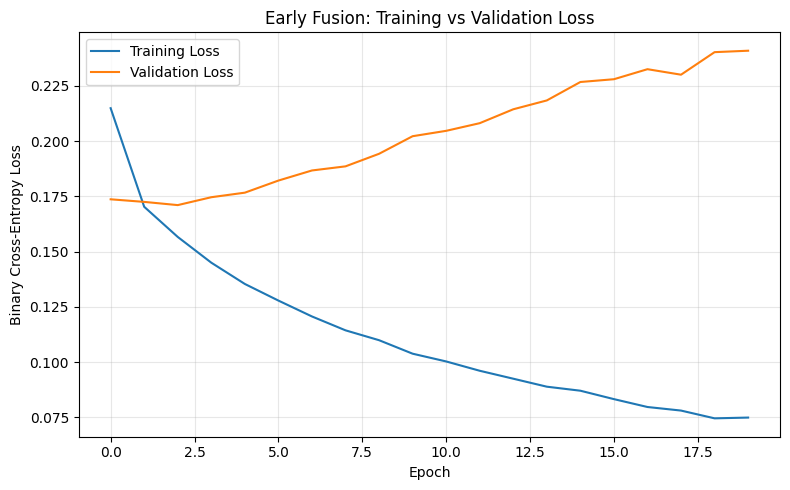

Best validation loss: 0.17102080591991123
Best epoch: 3


In [ ]:
# Plot the Early Fusion training and validation losses
plt.figure(figsize=(8, 5))

plt.plot(
    fusion_train_losses,
    label="Training Loss"
)

plt.plot(
    fusion_val_losses,
    label="Validation Loss"
)

plt.title("Early Fusion: Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Best validation loss:", min(fusion_val_losses))
print("Best epoch:", np.argmin(fusion_val_losses) + 1)


In [ ]:

# Compare training and validation losses across models

loss_summary = []

model_losses = {
    "Poster-only": (image_train_losses, image_val_losses),
    "Plot-only": (text_train_losses, text_val_losses),
    "Early Fusion": (fusion_train_losses, fusion_val_losses)
}

for model_name, (train_loss, val_loss) in model_losses.items():

    best_epoch = np.argmin(val_loss)

    loss_summary.append({
        "Model": model_name,
        "Best Epoch": int(best_epoch + 1),
        "Training Loss at Best Epoch": train_loss[best_epoch],
        "Best Validation Loss": val_loss[best_epoch],
        "Final Validation Loss": val_loss[-1]
    })

loss_summary_df = pd.DataFrame(loss_summary)

display(loss_summary_df.round(4))


,Model,Best Epoch,Training Loss at Best Epoch,Best Validation Loss,Final Validation Loss
0,Poster-only,1,0.2723,0.2479,0.4955
1,Plot-only,4,0.1624,0.1719,0.1938
2,Early Fusion,3,0.1566,0.1710,0.2409


In [ ]:
# Evaluate Early Fusion and compare validation results
fusion_results = evaluate_model(
    fusion_model,
    fusion_val_loader,
    threshold=0.5
)

comparison_df = pd.DataFrame(
    [image_results, text_results, fusion_results],
    index=[
        "Poster-only",
        "Plot-only",
        "Early Fusion"
    ]
)

display(comparison_df.round(4))


,Micro-F1,Macro-F1,Macro-AP
Poster-only,0.3875,0.1784,0.3141
Plot-only,0.6350,0.5405,0.6301
Early Fusion,0.6507,0.5613,0.6382


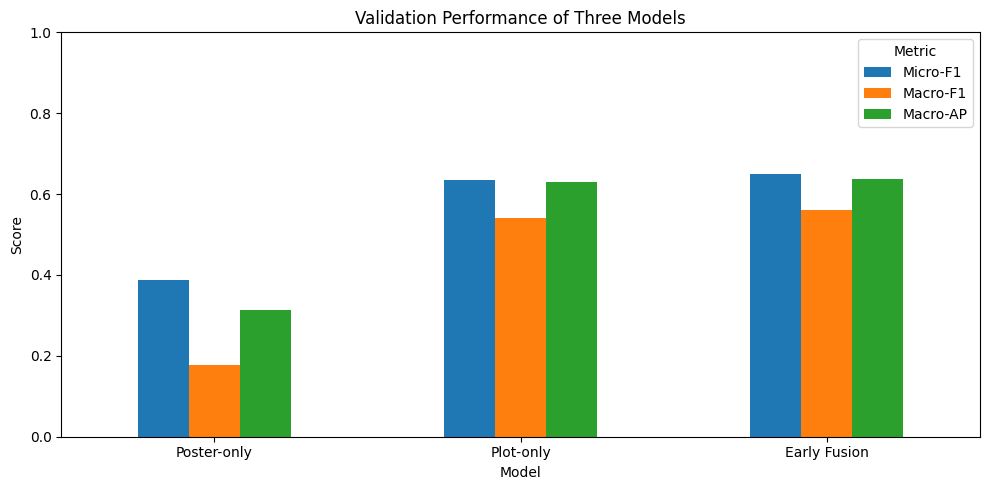

In [ ]:
# Plot the validation results for the first three models
ax = comparison_df.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title("Validation Performance of Three Models")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(title="Metric")

plt.tight_layout()
plt.show()


## 8. Late Fusion

Late Fusion combines the predictions from the separately trained Poster-only and Plot-only models.

Different weights from 0 to 1 are tested for the poster model using the validation data. Macro-F1 is used to find the best combination, with the prediction threshold initially set to 0.5. The best weight is then selected before adjusting the final prediction thresholds.

In [ ]:
# Collect prediction probabilities from each unimodal model
##  Late Fusion

def get_predictions(model, loader):
    model.eval()

    probabilities = []
    true_labels = []

    with torch.no_grad():
        for X, y in loader:
            X = X.to(device)

            logits = model(X)
            probs = torch.sigmoid(logits)

            probabilities.append(probs.cpu().numpy())
            true_labels.append(y.numpy())

    return (
        np.vstack(probabilities),
        np.vstack(true_labels)
    )


poster_probs, y_val = get_predictions(
    image_model, image_val_loader
)

plot_probs, y_val_text = get_predictions(
    text_model, text_val_loader
)

assert np.array_equal(y_val, y_val_text)

print("Poster probabilities:", poster_probs.shape)
print("Plot probabilities:", plot_probs.shape)
print("Validation labels:", y_val.shape)


Poster probabilities: (3894, 23)
Plot probabilities: (3894, 23)
Validation labels: (3894, 23)


In [ ]:
# Test different poster weights for Late Fusion
from sklearn.metrics import f1_score, average_precision_score

fusion_results_list = []

for alpha in np.arange(0, 1.01, 0.1):

    combined_probs = (
        alpha * poster_probs
        + (1 - alpha) * plot_probs
    )

    combined_preds = (
        combined_probs >= 0.5
    ).astype(int)

    micro_f1 = f1_score(
        y_val,
        combined_preds,
        average="micro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_val,
        combined_preds,
        average="macro",
        zero_division=0
    )

    macro_ap = average_precision_score(
        y_val,
        combined_probs,
        average="macro"
    )

    fusion_results_list.append({
        "Alpha": round(float(alpha), 2),
        "Micro-F1": micro_f1,
        "Macro-F1": macro_f1,
        "Macro-AP": macro_ap
    })


late_fusion_df = pd.DataFrame(fusion_results_list)

display(late_fusion_df.round(4))


,Alpha,Micro-F1,Macro-F1,Macro-AP
0,0.0,0.6350,0.5405,0.6301
1,0.1,0.6318,0.5329,0.6398
2,0.2,0.6225,0.5109,0.6448
3,0.3,0.6113,0.4886,0.6456
4,0.4,0.5903,0.4475,0.6428
5,0.5,0.5486,0.3744,0.6340
6,0.6,0.4956,0.2811,0.6147
7,0.7,0.4630,0.2367,0.5754
8,0.8,0.4351,0.2082,0.5077
9,0.9,0.4114,0.1925,0.4080


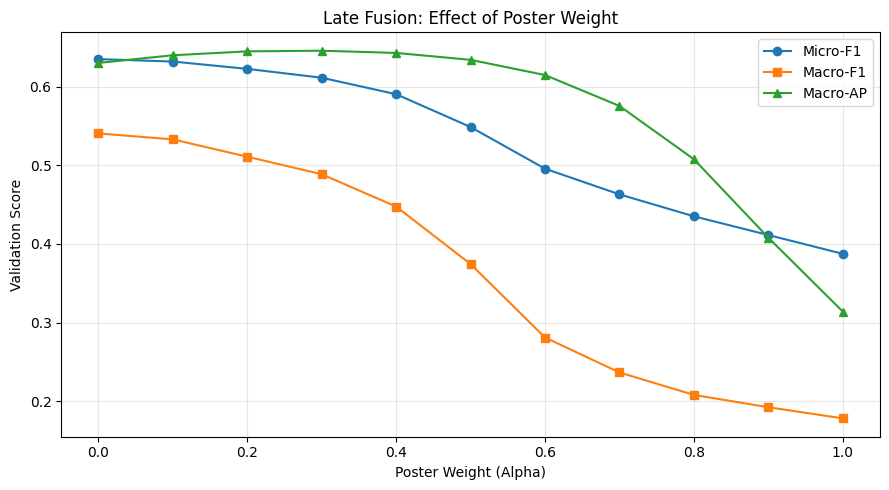

In [ ]:
# Plot how Late Fusion performance changes with poster weight
plt.figure(figsize=(9, 5))

plt.plot(
    late_fusion_df["Alpha"],
    late_fusion_df["Micro-F1"],
    marker="o",
    label="Micro-F1"
)

plt.plot(
    late_fusion_df["Alpha"],
    late_fusion_df["Macro-F1"],
    marker="s",
    label="Macro-F1"
)

plt.plot(
    late_fusion_df["Alpha"],
    late_fusion_df["Macro-AP"],
    marker="^",
    label="Macro-AP"
)

plt.title("Late Fusion: Effect of Poster Weight")
plt.xlabel("Poster Weight (Alpha)")
plt.ylabel("Validation Score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# Choosing the poster weight with the best validation Macro-F1
best_row = late_fusion_df.loc[
    late_fusion_df["Macro-F1"].idxmax()
]

best_alpha = float(best_row["Alpha"])

print("Best poster weight:", best_alpha)
print("Best plot weight:", 1 - best_alpha)
print("Validation Macro-F1:", best_row["Macro-F1"])


Best poster weight: 0.0
Best plot weight: 1.0
Validation Macro-F1: 0.5404506479501873


In [ ]:
# Combine predictions using the selected poster weight
late_probs = (
    best_alpha * poster_probs
    + (1 - best_alpha) * plot_probs
)

late_preds = (late_probs >= 0.5).astype(int)

late_results = {
    "Micro-F1": f1_score(
        y_val, late_preds,
        average="micro",
        zero_division=0
    ),
    "Macro-F1": f1_score(
        y_val, late_preds,
        average="macro",
        zero_division=0
    ),
    "Macro-AP": average_precision_score(
        y_val, late_probs,
        average="macro"
    )
}

print("Late fusion results:")
print(late_results)


Late fusion results:
{'Micro-F1': 0.6349502125429454, 'Macro-F1': 0.5404506479501873, 'Macro-AP': np.float64(0.6301039091215868)}


,Micro-F1,Macro-F1,Macro-AP
Poster-only,0.3875,0.1784,0.3141
Plot-only,0.6350,0.5405,0.6301
Early Fusion,0.6507,0.5613,0.6382
Late Fusion,0.6350,0.5405,0.6301


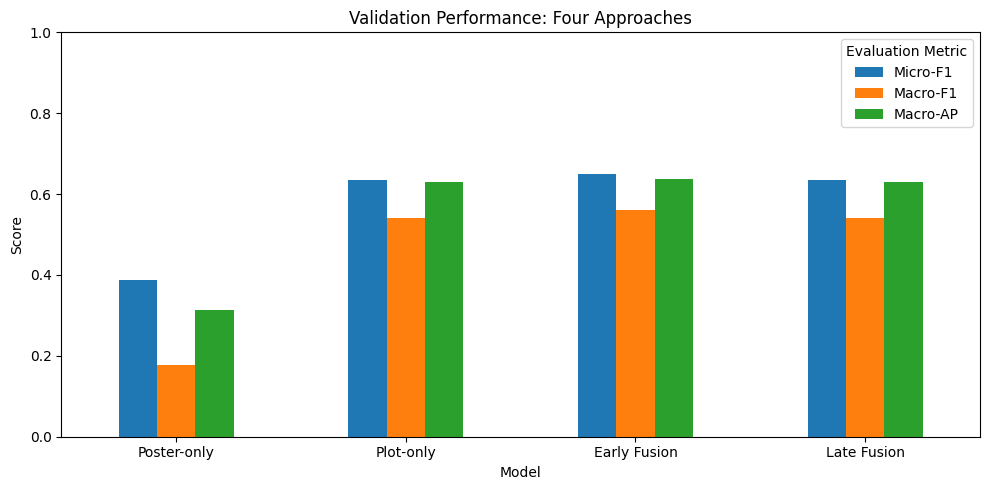

In [ ]:
# Compare validation results across all four approaches
final_validation_df = pd.DataFrame(
    [
        image_results,
        text_results,
        fusion_results,
        late_results
    ],
    index=[
        "Poster-only",
        "Plot-only",
        "Early Fusion",
        "Late Fusion"
    ]
)

display(final_validation_df.round(4))

ax = final_validation_df.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title("Validation Performance: Four Approaches")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(title="Evaluation Metric")

plt.tight_layout()
plt.show()


In [ ]:
# Save validation comparison results

final_validation_df.to_csv(
    output_dir / "validation_comparison.csv"
)

print("Validation comparison saved.")

Validation comparison saved.


## 9. Validation-Based Threshold Selection

Different prediction thresholds between 0.10 and 0.70 are tested on the validation data. Macro-F1 is used to choose the best threshold for each model.

This is important because movies can belong to multiple genres, and the usual threshold of 0.5 may not give the best balance between precision and recall.

In [ ]:
# Collect validation predictions for threshold selection

poster_val_probs, y_val = get_predictions(
    image_model, image_val_loader
)

plot_val_probs, y_val_text = get_predictions(
    text_model, text_val_loader
)

early_val_probs, y_val_early = get_predictions(
    fusion_model, fusion_val_loader
)

assert np.array_equal(y_val, y_val_text)
assert np.array_equal(y_val, y_val_early)

late_val_probs = (
    best_alpha * poster_val_probs
    + (1 - best_alpha) * plot_val_probs
)

validation_probs = {
    "Poster-only": poster_val_probs,
    "Plot-only": plot_val_probs,
    "Early Fusion": early_val_probs,
    "Late Fusion": late_val_probs
}

print("Validation predictions collected.")
print("Best late-fusion poster weight:", best_alpha)


Validation predictions collected.
Best late-fusion poster weight: 0.0


In [ ]:
# Test different classification thresholds on validation data
from sklearn.metrics import f1_score

thresholds = np.arange(0.10, 0.71, 0.05)

best_thresholds = {}
threshold_results = []

for model_name, probabilities in validation_probs.items():

    best_score = -1
    best_threshold = 0.5

    for threshold in thresholds:
        predictions = (
            probabilities >= threshold
        ).astype(int)

        score = f1_score(
            y_val,
            predictions,
            average="macro",
            zero_division=0
        )

        if score > best_score:
            best_score = score
            best_threshold = float(threshold)

    best_thresholds[model_name] = best_threshold

    threshold_results.append({
        "Model": model_name,
        "Best Threshold": best_threshold,
        "Validation Macro-F1": best_score
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Model,Best Threshold,Validation Macro-F1
0,Poster-only,0.15,0.3245
1,Plot-only,0.20,0.5974
2,Early Fusion,0.30,0.6009
3,Late Fusion,0.20,0.5974


,Model,Macro-F1 (0.5),Macro-F1 (Tuned)
0,Poster-only,0.1784,0.3245
1,Plot-only,0.5405,0.5974
2,Early Fusion,0.5613,0.6009
3,Late Fusion,0.5405,0.5974


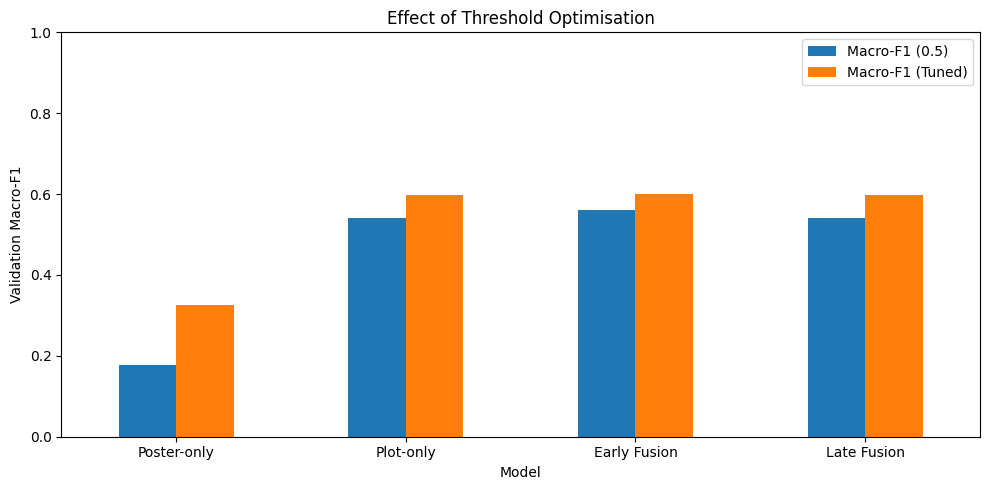

In [ ]:
# Evaluate the selected thresholds and compare metrics
from sklearn.metrics import average_precision_score

tuning_results = []

for name, probs in validation_probs.items():

    default_preds = (probs >= 0.5).astype(int)

    tuned_preds = (
        probs >= best_thresholds[name]
    ).astype(int)

    tuning_results.append({
        "Model": name,
        "Macro-F1 (0.5)": f1_score(
            y_val, default_preds,
            average="macro", zero_division=0
        ),
        "Macro-F1 (Tuned)": f1_score(
            y_val, tuned_preds,
            average="macro", zero_division=0
        )
    })

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df.round(4))

ax = tuning_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title("Effect of Threshold Optimisation")
ax.set_ylabel("Validation Macro-F1")
ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()


In [ ]:

# Save the final validation-selected late-fusion settings

late_config = {
    "poster_weight": float(best_alpha),
    "plot_weight": float(1 - best_alpha),
    "threshold": float(best_thresholds["Late Fusion"]),
    "selection_metric": "validation_macro_f1"
}

with open(
    output_dir / "late_fusion_config.json",
    "w"
) as file:
    json.dump(late_config, file, indent=4)

print("Final late-fusion configuration saved.")
print(late_config)


Final late-fusion configuration saved.
{'poster_weight': 0.0, 'plot_weight': 1.0, 'threshold': 0.20000000000000004, 'selection_metric': 'validation_macro_f1'}


##  Final Test Evaluation

All four models are tested on the test dataset using the settings chosen from the validation results.

Micro-F1, Macro-F1, Sample-F1, Macro Average Precision and Hamming Loss are used to compare the models and understand how well they predict multiple movie genres.

In [ ]:
# Prepare test data loaders for the trained models

image_test_loader = create_loader(
    image_scaled, test_idx
)

text_test_loader = create_loader(
    text_scaled, test_idx
)

fusion_test_loader = create_loader(
    fusion_features,
    test_idx,
    batch_size=64,
    shuffle=False
)

print("Test DataLoaders ready.")
print("Number of test movies:", len(test_idx))


Test DataLoaders ready.
Number of test movies: 3894


In [ ]:
# Generate test predictions for all four approaches
poster_test_probs, y_test = get_predictions(
    image_model, image_test_loader
)

plot_test_probs, y_test_text = get_predictions(
    text_model, text_test_loader
)

early_test_probs, y_test_early = get_predictions(
    fusion_model, fusion_test_loader
)

assert np.array_equal(y_test, y_test_text)
assert np.array_equal(y_test, y_test_early)

late_test_probs = (
    best_alpha * poster_test_probs
    + (1 - best_alpha) * plot_test_probs
)

test_probs = {
    "Poster-only": poster_test_probs,
    "Plot-only": plot_test_probs,
    "Early Fusion": early_test_probs,
    "Late Fusion": late_test_probs
}

print("All test predictions generated.")


All test predictions generated.


In [ ]:
# Calculate final test metrics using the selected settings
from sklearn.metrics import (
    f1_score,
    average_precision_score,
    hamming_loss
)

test_results = []

for name, probs in test_probs.items():

    predictions = (
        probs >= best_thresholds[name]
    ).astype(int)

    test_results.append({
        "Model": name,
        "Micro-F1": f1_score(
            y_test, predictions,
            average="micro", zero_division=0
        ),
        "Macro-F1": f1_score(
            y_test, predictions,
            average="macro", zero_division=0
        ),
        "Sample-F1": f1_score(
            y_test, predictions,
            average="samples", zero_division=0
        ),
        "Macro-AP": average_precision_score(
            y_test, probs,
            average="macro"
        ),
        "Hamming Loss": hamming_loss(
            y_test, predictions
        )
    })

test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(4))


,Model,Micro-F1,Macro-F1,Sample-F1,Macro-AP,Hamming Loss
0,Poster-only,0.4723,0.3241,0.4728,0.3165,0.1641
1,Plot-only,0.6394,0.5765,0.6373,0.6102,0.0959
2,Early Fusion,0.6607,0.5930,0.6618,0.6187,0.0826
3,Late Fusion,0.6394,0.5765,0.6373,0.6102,0.0959


In [ ]:
# Save the final test results and thresholds
test_results_df.to_csv(
    output_dir / "final_test_results.csv",
    index=False
)

threshold_df.to_csv(
    output_dir / "threshold_results.csv",
    index=False
)

print("Final test results saved successfully.")


Final test results saved successfully.


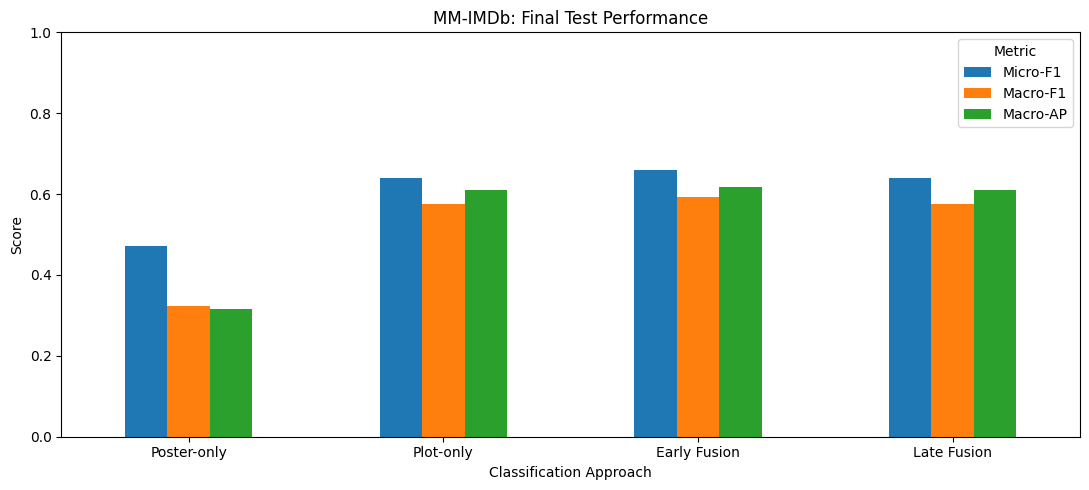

In [ ]:
# Plot the final test results for comparison
plot_df = test_results_df.set_index("Model")[
    ["Micro-F1", "Macro-F1", "Macro-AP"]
]

ax = plot_df.plot(
    kind="bar",
    figsize=(11, 5),
    rot=0
)

ax.set_title("MM-IMDb: Final Test Performance")
ax.set_xlabel("Classification Approach")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(title="Metric")

plt.tight_layout()

plt.savefig(
    output_dir / "final_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


##  Genre-Level Performance and Error Analysis

F1 scores for each genre and predictions for individual movies are reviewed to understand where the four models perform well and where they struggle.

This is important because some genres in MM-IMDb have fewer examples than others, and the overall results may not clearly show how well the models predict these less common genres.

In [ ]:

# Calculate performance separately for each genre

from sklearn.metrics import (
    precision_recall_fscore_support,
    average_precision_score
)

genre_results = []

for model_name, probs in test_probs.items():

    predictions = (
        probs >= best_thresholds[model_name]
    ).astype(int)

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_test,
            predictions,
            average=None,
            zero_division=0
        )
    )

    for genre_idx in range(y_test.shape[1]):

        genre_ap = average_precision_score(
            y_test[:, genre_idx],
            probs[:, genre_idx]
        )

        genre_results.append({
            "Model": model_name,
            "Genre": genre_idx,
            "Precision": precision[genre_idx],
            "Recall": recall[genre_idx],
            "F1": f1[genre_idx],
            "Average Precision": genre_ap,
            "Support": support[genre_idx]
        })

genre_results_df = pd.DataFrame(genre_results)

display(genre_results_df.round(4))

genre_results_df.to_csv(
    output_dir / "per_genre_results.csv",
    index=False
)


,Model,Genre,Precision,Recall,F1,Average Precision,Support
0,Poster-only,0,0.5557,0.9981,0.7140,0.7347,2133
1,Poster-only,1,0.4233,0.8941,0.5746,0.6743,1247
2,Poster-only,2,0.3075,0.7210,0.4311,0.3877,792
3,Poster-only,3,0.3041,0.8262,0.4445,0.4150,771
4,Poster-only,4,0.2382,0.6602,0.3501,0.3237,565
...,...,...,...,...,...,...,...
87,Late Fusion,18,0.3185,0.3597,0.3378,0.3485,139
88,Late Fusion,19,0.6774,0.6923,0.6848,0.7365,91
89,Late Fusion,20,0.7000,0.7071,0.7035,0.7141,99
90,Late Fusion,21,0.3793,0.3729,0.3761,0.3301,59


Model,Early Fusion,Late Fusion,Plot-only,Poster-only
Genre,,,,
0,0.7994,0.7761,0.7761,0.7140
1,0.6973,0.6506,0.6506,0.5746
2,0.5572,0.5599,0.5599,0.4311
3,0.6341,0.5928,0.5928,0.4445
4,0.6249,0.6144,0.6144,0.3501
5,0.6376,0.6001,0.6001,0.4152
6,0.5536,0.5584,0.5584,0.3780
7,0.7318,0.7076,0.7076,0.4537
8,0.7686,0.7945,0.7945,0.3141


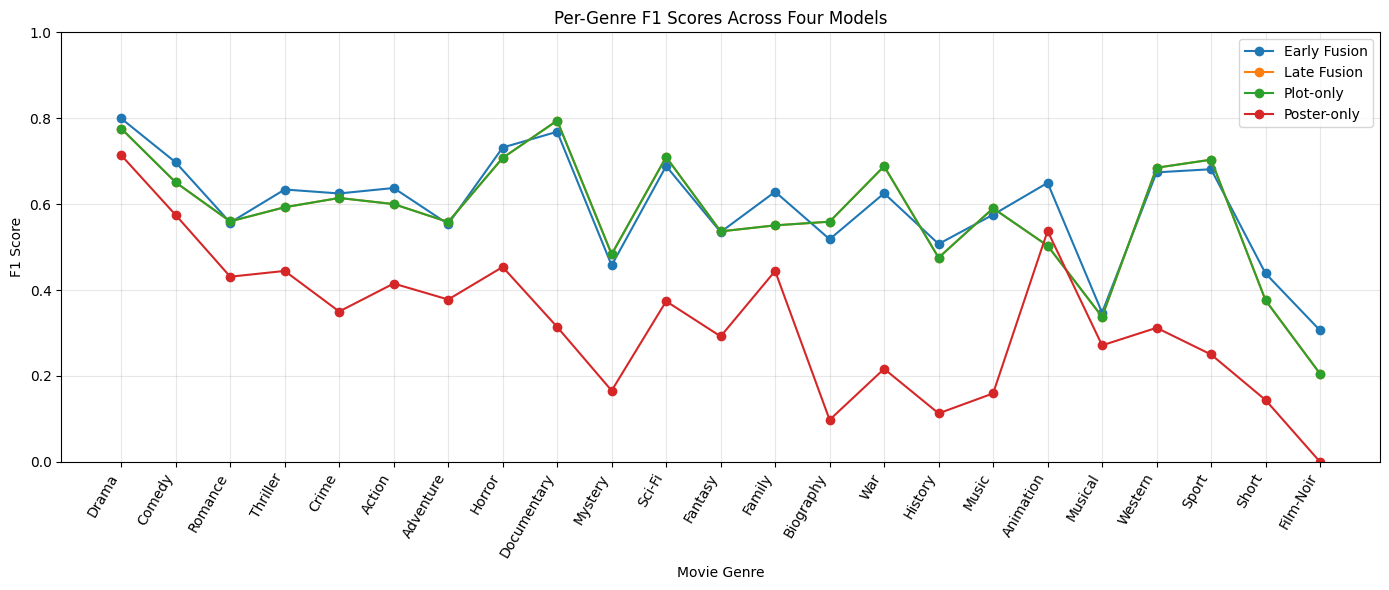

In [ ]:

# Compare per-genre F1 scores across the four models

genre_f1_comparison = genre_results_df.pivot(
    index="Genre",
    columns="Model",
    values="F1"
)

# Ensure genre indices match the original dataset order
assert set(genre_f1_comparison.index) == set(range(len(genre_names)))

genre_f1_comparison = genre_f1_comparison.reindex(
    range(len(genre_names))
)

display(genre_f1_comparison.round(4))

plt.figure(figsize=(14, 6))

for model_name in genre_f1_comparison.columns:
    plt.plot(
        range(len(genre_names)),
        genre_f1_comparison[model_name],
        marker="o",
        label=model_name
    )

plt.title("Per-Genre F1 Scores Across Four Models")
plt.xlabel("Movie Genre")
plt.ylabel("F1 Score")

plt.xticks(
    range(len(genre_names)),
    genre_names,
    rotation=60,
    ha="right"
)

plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# Convert genre indices into names and inspect movie predictions
def get_genre_names(label_indices):
    return [genre_names[int(i)] for i in label_indices]

# Compare Early Fusion and Plot-only predictions for each movie

from sklearn.metrics import f1_score

early_preds = (
    early_test_probs >= best_thresholds["Early Fusion"]
).astype(int)

plot_preds = (
    plot_test_probs >= best_thresholds["Plot-only"]
).astype(int)

# Calculate F1 score for each movie
early_sample_f1 = np.array([
    f1_score(y_test[i], early_preds[i], zero_division=0)
    for i in range(len(y_test))
])

plot_sample_f1 = np.array([
    f1_score(y_test[i], plot_preds[i], zero_division=0)
    for i in range(len(y_test))
])

# Identify movies where Early Fusion performs better
improvement = early_sample_f1 - plot_sample_f1

better_movies = np.where(improvement > 0)[0]

# Select the three largest improvements
selected_movies = better_movies[
    np.argsort(improvement[better_movies])[::-1][:3]
]

print("Movies where Early Fusion performs better:",
      len(better_movies))

print("Selected test positions:", selected_movies)


Movies where Early Fusion performs better: 1501
Selected test positions: [3650 3525 1002]


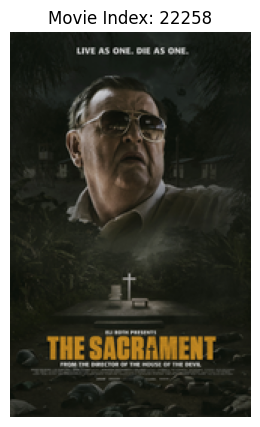

Plot Summary:
the journalist patrick works at the vice , a company dedicated to cover bizarre news . when his sister caroline joins a community , she travels abroad with her new family . out of the blue , caroline invites her brother to visit her in an undefined country and patrick travels by helicopter with his friends jake and sam that work with him at vice . they find weird that the men that have come to guide them to the eden parish have guns . on the arrival to the camp , patrick , sam and jake find a community of happy people that worship father . they interview father but soon they realize that peopl

Actual Genres: ['Thriller', 'Horror']
Plot-only Predictions: ['Drama', 'Comedy', 'Adventure', 'Fantasy']
Early Fusion Predictions: ['Drama', 'Thriller', 'Horror']


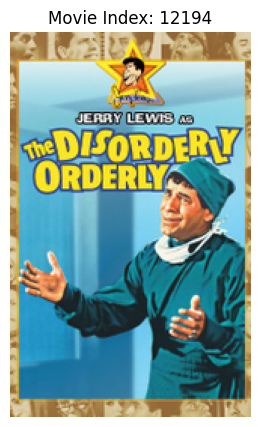

Plot Summary:
jerome littlefield works at a local hospital as an orderly . he was once a promising medical student but was forced to quit medical school when his empathy for his ill patients had him developing their symptoms . he ' s undergone sessions with a hospital psychiatrist and has the support of both his girlfriend , nurse julie blair , and the hospital administrator , dr . jean howard , but no one has been able to get to the root of his problem . jerome is surprised when his high school dream girl , susan andrews , is admitted to the hospital after a suicide attempt . she treats him very badly and 

Actual Genres: ['Comedy', 'Romance']
Plot-only Predictions: ['Drama', 'Thriller']
Early Fusion Predictions: ['Drama', 'Comedy', 'Romance']


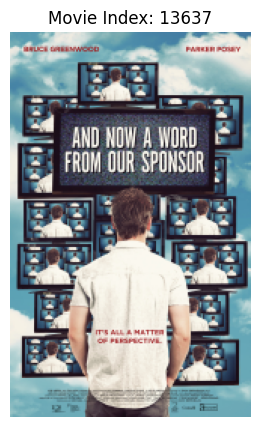

Plot Summary:
an advertising ceo is found mysteriously unconscious in front of a wall of tvs in an electronics store . when he wakes up in the hospital , he is only able to communicate through advertising slogans . taken in by the head of the hospital ' s charity foundation , he begins to have a profound affect on her life and the strained relationship she has with her daughter .

Actual Genres: ['Drama', 'Comedy']
Plot-only Predictions: ['Drama', 'Romance', 'Thriller', 'Horror', 'Mystery']
Early Fusion Predictions: ['Drama', 'Comedy']


In [ ]:

# Display examples where Early Fusion improves predictions

with h5py.File(hdf5_path, "r") as f:

    for position in selected_movies:

        # Find the movie's original dataset index
        movie_idx = test_idx[position]

        # Load poster and plot
        image = f["images"][movie_idx]
        sequence = f["sequences"][movie_idx]

        poster = restore_poster(image)

        plot = decode_sequence(sequence)

        # Get actual and predicted genres
        actual = np.where(y_test[position] == 1)[0]
        predicted_plot = np.where(plot_preds[position] == 1)[0]
        predicted_early = np.where(early_preds[position] == 1)[0]

        # Display poster
        plt.figure(figsize=(4, 5))
        plt.imshow(poster)
        plt.title(f"Movie Index: {movie_idx}")
        plt.axis("off")
        plt.show()

        # Display plot summary
        print("Plot Summary:")
        print(plot[:600])

        print("\nActual Genres:", get_genre_names(actual))

        print(
            "Plot-only Predictions:",
            get_genre_names(predicted_plot)
        )

        print(
            "Early Fusion Predictions:",
            get_genre_names(predicted_early)
        )



In [ ]:

# Compare movie-level performance of Early Fusion and Plot-only

early_better = np.sum(early_sample_f1 > plot_sample_f1)
plot_better = np.sum(plot_sample_f1 > early_sample_f1)
equal_performance = np.sum(early_sample_f1 == plot_sample_f1)

comparison_summary = pd.DataFrame({
    "Result": [
        "Early Fusion better",
        "Plot-only better",
        "Equal performance"
    ],
    "Number of Movies": [
        early_better,
        plot_better,
        equal_performance
    ]
})

display(comparison_summary)

print("Total test movies:",
      len(y_test))


,Result,Number of Movies
0,Early Fusion better,1501
1,Plot-only better,986
2,Equal performance,1407


Total test movies: 3894


## Consistency Across Training Runs

The Poster-only, Plot-only and Early Fusion models are trained again using three different random seeds (42, 123 and 456). The dataset split and extracted features remain the same for all runs.

The average validation Macro-F1 and standard deviation are calculated to check how much the results change between runs. These results are used to check training consistency and are separate from the final test results.

In [ ]:

# Repeat model training with different random seeds

seeds = [42, 123, 456]
seed_results = []

for seed in seeds:

    print("\nRandom seed:", seed)

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Create training loaders with the current seed
    image_loader = create_loader(
    image_scaled, train_idx, shuffle=True
    )

    text_loader = create_loader(
    text_scaled, train_idx, shuffle=True
    )


    fusion_loader = create_loader(
        fusion_features, train_idx, shuffle=True
    )

    # Initialise new classification models
    models = {
        "Poster-only": (
            GenreClassifier(2048).to(device),
            image_loader,
            image_val_loader
        ),
        "Plot-only": (
            GenreClassifier(768).to(device),
            text_loader,
            text_val_loader
        ),
        "Early Fusion": (
            EarlyFusionClassifier().to(device),
            fusion_loader,
            fusion_val_loader
        )
    }

    for model_name, (model, train_loader, val_loader) in models.items():

        model, _, _ = train_model(
            model,
            train_loader,
            val_loader,
            epochs=20
        )

        probs, true_labels = get_predictions(
            model, val_loader
        )

        # Select threshold using validation Macro-F1
        best_score = -1

        for threshold in thresholds:
            predictions = (probs >= threshold).astype(int)

            score = f1_score(
                true_labels,
                predictions,
                average="macro",
                zero_division=0
            )

            best_score = max(best_score, score)

        seed_results.append({
            "Seed": seed,
            "Model": model_name,
            "Validation Macro-F1": best_score
        })

seed_results_df = pd.DataFrame(seed_results)

display(seed_results_df.round(4))



Random seed: 42
Epoch 1/20 | Train Loss: 0.2745 | Val Loss: 0.2484
Epoch 2/20 | Train Loss: 0.2302 | Val Loss: 0.2501
Epoch 3/20 | Train Loss: 0.2131 | Val Loss: 0.2565
Epoch 4/20 | Train Loss: 0.1981 | Val Loss: 0.2669
Epoch 5/20 | Train Loss: 0.1840 | Val Loss: 0.2785
Epoch 6/20 | Train Loss: 0.1711 | Val Loss: 0.2935
Epoch 7/20 | Train Loss: 0.1594 | Val Loss: 0.3055
Epoch 8/20 | Train Loss: 0.1485 | Val Loss: 0.3194
Epoch 9/20 | Train Loss: 0.1390 | Val Loss: 0.3326
Epoch 10/20 | Train Loss: 0.1298 | Val Loss: 0.3493
Epoch 11/20 | Train Loss: 0.1218 | Val Loss: 0.3648
Epoch 12/20 | Train Loss: 0.1148 | Val Loss: 0.3783
Epoch 13/20 | Train Loss: 0.1082 | Val Loss: 0.3925
Epoch 14/20 | Train Loss: 0.1031 | Val Loss: 0.4090
Epoch 15/20 | Train Loss: 0.0965 | Val Loss: 0.4281
Epoch 16/20 | Train Loss: 0.0936 | Val Loss: 0.4356
Epoch 17/20 | Train Loss: 0.0896 | Val Loss: 0.4528
Epoch 18/20 | Train Loss: 0.0844 | Val Loss: 0.4671
Epoch 19/20 | Train Loss: 0.0812 | Val Loss: 0.4800
Epoc

,Seed,Model,Validation Macro-F1
0,42,Poster-only,0.3241
1,42,Plot-only,0.6049
2,42,Early Fusion,0.5928
3,123,Poster-only,0.3194
4,123,Plot-only,0.5953
5,123,Early Fusion,0.5853
6,456,Poster-only,0.3266
7,456,Plot-only,0.5904
8,456,Early Fusion,0.5973


In [ ]:

# Summarise the results using the mean and standard deviation

seed_summary = seed_results_df.groupby("Model")[
    "Validation Macro-F1"
].agg(["mean", "std"])

display(seed_summary.round(4))

seed_summary.to_csv(
    output_dir / "seed_stability_results.csv"
)


,mean,std
Model,,
Early Fusion,0.5918,0.0061
Plot-only,0.5969,0.0074
Poster-only,0.3234,0.0037
